# Is Philippine Economic Growth Creating Real Jobs? — Initial Insights

**Milestone 4 · Phase 4 (Weeks 13–16)**

**Problem statement.** Can quarter-to-quarter changes in the Philippines' national underemployment rate
be anticipated from GDP growth and inflation (CPI)?

**Audience.** Labor and economic planners (DOLE, NEDA / DEPDev), labor policy researchers, journalists.

**Data.** `data/processed/analysis_quarterly.csv` — one row per quarter, 2005Q2–2025Q4 (83 quarters),
built from PSA OpenSTAT by `scripts/transform.py`. Column meanings are in
[`data/data_dictionary.md`](../data/data_dictionary.md).

**How this notebook is organized**

1. Summary statistics — what the key measures look like (Week 13)
2. Four charts, each with Observation / Implication / Possible Action (Weeks 14 and 16)
3. Inference check — one relationship, tested carefully (Week 15)
4. Overall takeaway

**Read the numbers with these caveats in mind**

- Each quarter's underemployment figure is the survey round in its first month (January, April, July,
  October). The survey went monthly in 2021; from then on the round-month value sits about
  **1.17 pp above** the three-month average ([cleaning log, entry 2](../data/cleaning_log.md)).
- The 2020–2021 pandemic quarters are real data, kept on purpose. They are extreme, and they are flagged
  wherever they could dominate a result.
- National figures only. Regions can behave very differently.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("../data/processed/analysis_quarterly.csv")
FIG_DIR = Path("../output/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA, parse_dates=["quarter_start_date"])

# One accent, one highlight, one neutral; colorblind-safe pair (blue / orange).
BLUE, ORANGE, GREY, INK = "#2a78d6", "#eb6834", "#898781", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
})

COVID = df["quarter_id"].between("2020Q1", "2021Q4")
COVID_START, COVID_END = pd.Timestamp("2020-01-01"), pd.Timestamp("2021-12-31")
print(f"{len(df)} quarters, {df['quarter_id'].iloc[0]} to {df['quarter_id'].iloc[-1]}")

83 quarters, 2005Q2 to 2025Q4


## 1. Summary Statistics (Week 13)

Five measures carry the problem statement. Everything else in the file is context or a lagged copy.

| Measure | Why it matters here |
| --- | --- |
| `underemployment_rate` | the headline level: % of employed people who want more hours or better work |
| `underemployment_change_qoq` | **the thing we want to anticipate**: this quarter's rate minus last quarter's, in percentage points (pp) |
| `gdp_growth_yoy` | predictor 1: GDP growth versus the same quarter a year earlier |
| `inflation_yoy` | predictor 2: consumer prices versus a year earlier |
| `growth_employment_gap` | the project KPI: GDP growth + the year-on-year change in underemployment. High = the economy grew and job quality did not follow |

Mode is left out on purpose: these are continuous measures recorded to three or four decimals, so almost no
value repeats and a mode says nothing. Median and percentiles describe the "typical quarter" better.

In [2]:
KEY = ["underemployment_rate", "underemployment_change_qoq", "gdp_growth_yoy",
       "inflation_yoy", "growth_employment_gap"]
s = df.set_index("quarter_id")[KEY]

summary = pd.DataFrame({
    "n": s.count(),
    "mean": s.mean(),
    "median": s.median(),
    "std dev": s.std(),
    "min": s.min(),
    "min quarter": s.idxmin(),
    "p10": s.quantile(0.10),
    "p90": s.quantile(0.90),
    "max": s.max(),
    "max quarter": s.idxmax(),
    "skew": s.skew(),
})
summary.round(2)

,n,mean,median,std dev,min,min quarter,p10,p90,max,max quarter,skew
underemployment_rate,83,17.64,18.02,3.04,11.71,2023Q4,13.40,21.08,26.14,2005Q2,0.12
underemployment_change_qoq,82,-0.17,0.04,2.07,-5.66,2005Q3,-3.10,2.03,4.26,2006Q2,-0.30
gdp_growth_yoy,83,5.06,6.10,4.04,-16.90,2020Q2,2.12,7.50,12.00,2021Q2,-3.42
inflation_yoy,83,3.80,3.54,2.02,-0.06,2015Q3,1.40,6.41,10.28,2008Q3,0.80
growth_employment_gap,79,4.64,5.17,3.82,-11.32,2020Q2,0.45,8.28,11.08,2012Q3,-1.65


### Key measure 1: `underemployment_rate` (%)
- **Mean:** 17.64 · **Median:** 18.02 · **Std dev:** 3.04
- **Min / Max:** 11.71 (2023Q4) / 26.14 (2005Q2)
- **Interpretation:** In a typical quarter roughly one in six working Filipinos wanted more hours or a
  better job. Mean and median are close and skew is near zero, so the level is not distorted by a few
  extreme quarters. The wide range (a 14-point spread) is mostly a slow downward trend over twenty
  years, which Chart 1 shows.

### Key measure 2: `underemployment_change_qoq` (pp) — the target
- **Mean:** −0.17 · **Median:** +0.04 · **Std dev:** 2.07
- **Min / Max:** −5.66 (2005Q3) / +4.26 (2006Q2)
- **Interpretation:** The average quarter barely moves the rate, but single quarters swing by ±2 pp
  as a matter of routine. The swings are ten times bigger than the average drift. Anyone reading one
  quarter's change as a trend will be wrong often. Part of that swing is the calendar, shown below.

### Key measure 3: `gdp_growth_yoy` (%)
- **Mean:** 5.06 · **Median:** 6.10 · **Std dev:** 4.04
- **Min / Max:** −16.9 (2020Q2) / +12.0 (2021Q2)
- **Interpretation:** The economy usually grows about 6 % a year. The mean understates that because
  the 2020 lockdown quarters pull it down (skew −3.4). The median is the honest "typical quarter" here.
  The 12.0 % peak in 2021Q2 is a rebound measured against the collapsed 2020Q2 base, not a boom.

### Key measure 4: `inflation_yoy` (%)
- **Mean:** 3.80 · **Median:** 3.54 · **Std dev:** 2.02
- **Min / Max:** −0.06 (2015Q3) / 10.28 (2008Q3)
- **Interpretation:** Inflation usually sits in the 2–4 % range. It is right-skewed (+0.8): a few
  price shocks (the 2008 rice and oil spike, the 2022–23 food surge) pull the mean above the median.

### Key measure 5: `growth_employment_gap` (pp)
- **Mean:** 4.64 · **Median:** 5.17 · **Std dev:** 3.82 · **n = 79** (needs four quarters of history)
- **Min / Max:** −11.32 (2020Q2) / +11.08 (2012Q3)
- **Interpretation:** Most of the time the gap is close to GDP growth itself, because underemployment
  moves much less than GDP. Its lowest values are all pandemic quarters, where GDP collapsed. The top of
  the range marks quarters where strong growth came with *higher* underemployment than a year before.

### Outliers

Flagged with the standard 1.5 × IQR rule (a value more than 1.5 interquartile ranges outside the middle
half of the data). They are listed, not removed: every one is a real published figure.

In [3]:
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    fence = 1.5 * (q3 - q1)
    return series[(series < q1 - fence) | (series > q3 + fence)].round(2)

for col in KEY:
    out = iqr_outliers(s[col].dropna())
    print(f"{col:28s} {len(out)} outlier(s): {out.to_dict()}")

underemployment_rate         1 outlier(s): {'2005Q2': 26.14}
underemployment_change_qoq   3 outlier(s): {'2005Q3': -5.66, '2006Q2': 4.26, '2021Q4': -4.97}
gdp_growth_yoy               8 outlier(s): {'2009Q1': 1.1, '2009Q3': 0.9, '2020Q1': -0.7, '2020Q2': -16.9, '2020Q3': -11.6, '2020Q4': -8.2, '2021Q1': -3.8, '2021Q2': 12.0}
inflation_yoy                5 outlier(s): {'2008Q2': 8.31, '2008Q3': 10.28, '2008Q4': 8.88, '2022Q4': 7.9, '2023Q1': 8.3}
growth_employment_gap        4 outlier(s): {'2020Q2': -11.32, '2020Q3': -7.96, '2020Q4': -6.56, '2021Q1': -2.63}


**What the outliers say.** GDP and the gap are dominated by the 2020–21 pandemic quarters, plus the
2009 global-crisis slowdown. Inflation's outliers are the 2008 and 2022–23 price shocks. The
target's outliers (2005Q3, 2006Q2, 2021Q4) are single large survey-to-survey jumps. None are errors,
so they stay in. Section 3 checks whether the main result changes without the pandemic quarters.

### Does the quarter of the year matter?

If underemployment moves the same way in the same quarter every year, that pattern is seasonal, not
economic, and it has to be separated out before asking whether GDP or inflation explains anything.

In [4]:
season = (df.groupby("quarter_num")["underemployment_change_qoq"]
            .agg(mean="mean", median="median", std="std", quarters="count",
                 share_rising=lambda x: (x > 0).mean())
            .round(2))
season

,mean,median,std,quarters,share_rising
quarter_num,,,,,
1,0.72,0.75,1.19,20,0.65
2,-0.03,-0.13,1.85,20,0.38
3,0.34,0.20,2.24,21,0.67
4,-1.67,-1.16,2.06,21,0.33


**Interpretation.** The fourth quarter stands out: underemployment fell by 1.67 pp on average and fell
in 14 of 21 years. The first quarter tends to give some of that back (+0.72 pp, rising in 13 of 20 years).
A Q4 drop is therefore normal, and not by itself evidence that job quality improved. Every comparison
below either removes this pattern or compares the same quarter across years.

## 2. Charts (Weeks 14 and 16)

Each chart answers one part of the question, in the order a reader needs them.

| Chart | Question it answers | Chart type | Main columns |
| --- | --- | --- | --- |
| 1 | Over twenty years, did growth come with better jobs? | two stacked line panels, shared time axis | `quarter_start_date`, `underemployment_rate`, `gdp_growth_yoy` |
| 2 | How much of the quarter-to-quarter movement is just the calendar? | bar (mean) with each year as a dot | `quarter_num`, `underemployment_change_qoq` |
| 3 | Does last quarter's GDP growth or inflation anticipate the next change? | two scatter panels | `gdp_growth_yoy_lag1`, `inflation_yoy_lag1`, seasonally adjusted change |
| 4 | How often does the economy grow while underemployment worsens? | bar per quarter, highlighted | `quarter_start_date`, `growth_employment_gap`, `underemployment_change_yoy` |

All four are saved to `output/figures/`.

### Chart 1 — The long view

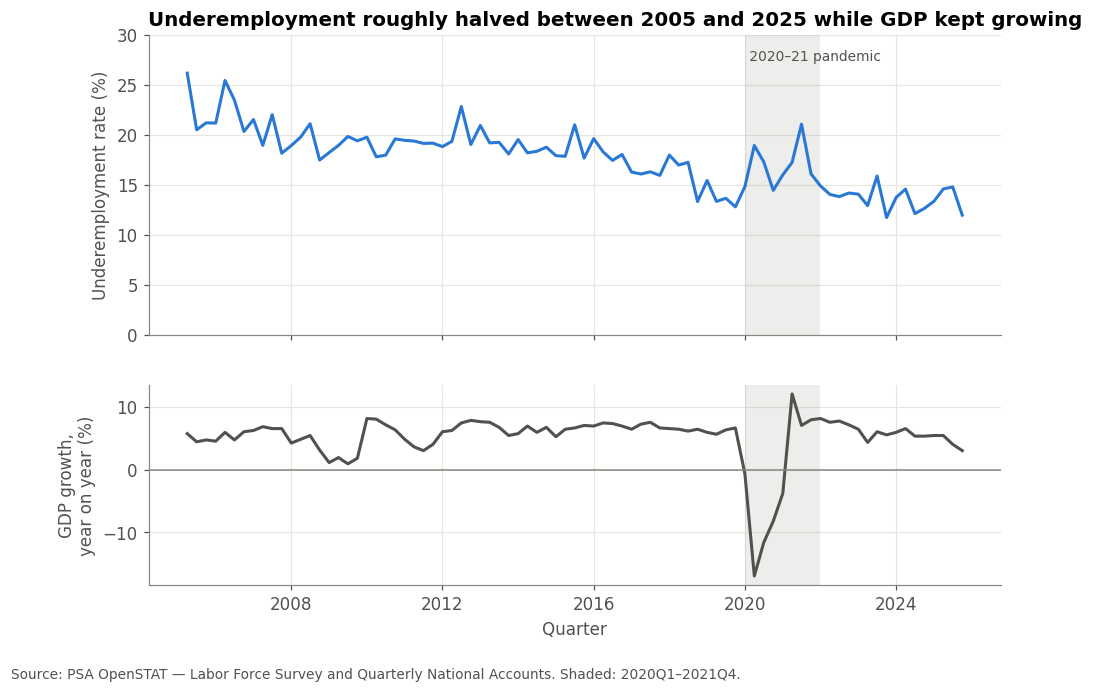

In [5]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True,
                                  gridspec_kw={"height_ratios": [3, 2]})
for ax in (top, bottom):
    ax.axvspan(COVID_START, COVID_END, color=GREY, alpha=0.15, lw=0)

top.plot(df["quarter_start_date"], df["underemployment_rate"], color=BLUE, lw=2)
top.set_ylabel("Underemployment rate (%)")
top.set_ylim(0, 30)
top.set_title("Underemployment roughly halved between 2005 and 2025 while GDP kept growing")
top.text(COVID_START, 28.5, " 2020–21 pandemic", color=INK, fontsize=9, va="top")

bottom.plot(df["quarter_start_date"], df["gdp_growth_yoy"], color=INK, lw=2)
bottom.axhline(0, color=GREY, lw=1)
bottom.set_ylabel("GDP growth,\nyear on year (%)")
bottom.set_xlabel("Quarter")

fig.text(0, -0.02, "Source: PSA OpenSTAT — Labor Force Survey and Quarterly National Accounts. "
         "Shaded: 2020Q1–2021Q4.", fontsize=9, color=INK)
fig.savefig(FIG_DIR / "01_underemployment_and_gdp_2005_2025.png")
plt.show()

**Observation.** Underemployment fell from 26.1 % in 2005Q2 to 11.7 % at its low in 2023Q4, and
stood at 13.7 % on average in 2025. Over the same years GDP grew in every quarter except the 2020–21
pandemic, usually by 5–7 %. The decline was not steady: the rate hovered between 18 and 20 % from
2008 to 2016, dropped in 2017–2019, jumped during the pandemic, then fell again.

**Implication.** Over two decades, growth and better job quality did go together. But the flat stretch
from 2008 to 2016, years of solid 6–7 % growth, shows that growth alone did not reliably bring
underemployment down in any given period. The long-run link is not a quarter-to-quarter rule.

**Possible action.** DOLE and NEDA reports should present the underemployment rate next to GDP growth
rather than citing GDP growth as evidence of labor-market improvement. The 2008–2016 plateau is worth a
closer look by sector to see which kinds of work stayed underemployed while output grew.

### Chart 2 — The calendar effect

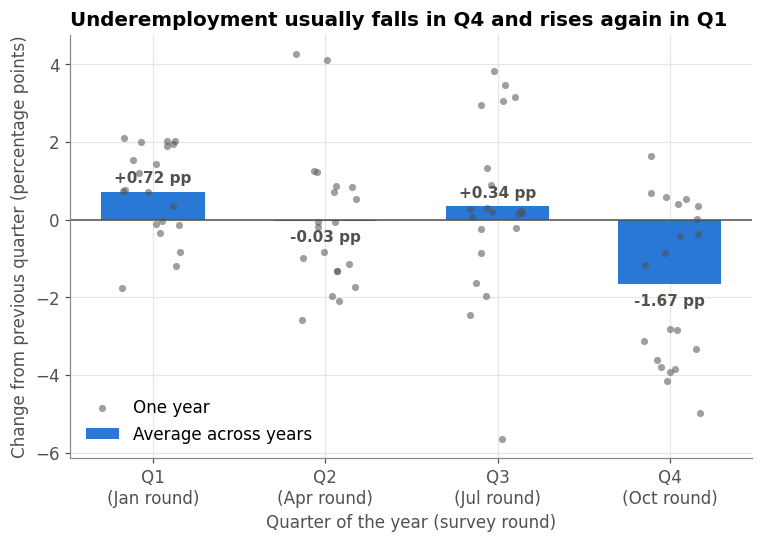

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
labels = ["Q1\n(Jan round)", "Q2\n(Apr round)", "Q3\n(Jul round)", "Q4\n(Oct round)"]
ax.bar(season.index, season["mean"], width=0.6, color=BLUE, label="Average across years")
rng_jitter = np.random.default_rng(0)
for q, grp in df.dropna(subset=["underemployment_change_qoq"]).groupby("quarter_num"):
    ax.scatter(q + rng_jitter.uniform(-0.18, 0.18, len(grp)), grp["underemployment_change_qoq"],
               s=22, color=INK, alpha=0.55, lw=0, label="One year" if q == 1 else None)
ax.axhline(0, color=INK, lw=1)
for q, m in season["mean"].items():
    ax.annotate(f"{m:+.2f} pp", (q, m), xytext=(0, 6 if m >= 0 else -14),
                textcoords="offset points", ha="center", fontsize=10, fontweight="bold", color=INK)
ax.set_xticks(season.index, labels)
ax.set_ylabel("Change from previous quarter (percentage points)")
ax.set_xlabel("Quarter of the year (survey round)")
ax.set_title("Underemployment usually falls in Q4 and rises again in Q1")
ax.legend(frameon=False, loc="lower left")
fig.savefig(FIG_DIR / "02_seasonal_pattern_by_quarter.png")
plt.show()

**Observation.** On average, underemployment drops 1.67 pp from the July round to the October round
and rises 0.72 pp from October to the following January. The dots show this is a tendency, not a law:
Q4 fell in 14 of 21 years, and every quarter has years that went the other way by 2 pp or more.

**Implication.** A falling rate in an October release is mostly what October always does. Comparing a
quarter only with the one before it mixes the calendar with real change. That is why the test in
Section 3 removes this seasonal average first.

**Possible action.** Communicate each new LFS release against the **same quarter a year earlier**
(e.g. October 2025 vs October 2024), and treat a quarter-on-quarter drop in Q4 as unremarkable unless it
is well beyond the usual −1.7 pp.

### Chart 3 — Does the economy anticipate the next move?

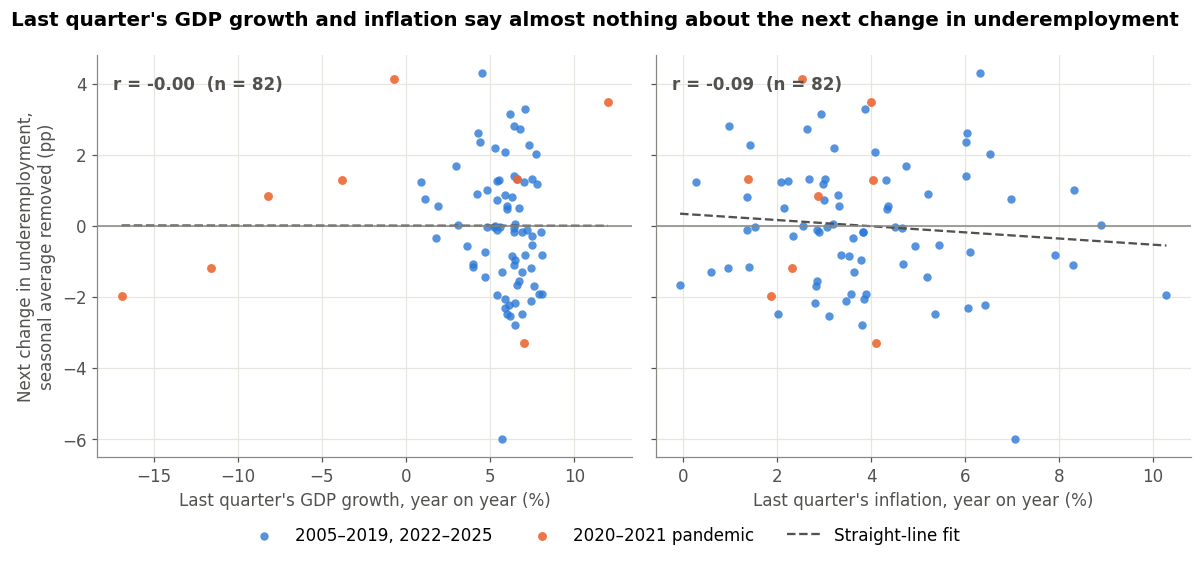

In [7]:
df["change_adj"] = (df["underemployment_change_qoq"]
                    - df.groupby("quarter_num")["underemployment_change_qoq"].transform("mean"))

panels = [("gdp_growth_yoy_lag1", "Last quarter's GDP growth, year on year (%)"),
          ("inflation_yoy_lag1", "Last quarter's inflation, year on year (%)")]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, (col, xlabel) in zip(axes, panels):
    pair = df[[col, "change_adj"]].dropna()
    normal = ~COVID[pair.index]
    ax.scatter(pair.loc[normal, col], pair.loc[normal, "change_adj"], s=30, color=BLUE,
               alpha=0.8, lw=0, label="2005–2019, 2022–2025")
    ax.scatter(pair.loc[~normal, col], pair.loc[~normal, "change_adj"], s=34, color=ORANGE,
               alpha=0.9, lw=0, label="2020–2021 pandemic")
    slope, intercept = np.polyfit(pair[col], pair["change_adj"], 1)
    xs = np.linspace(pair[col].min(), pair[col].max(), 50)
    ax.plot(xs, intercept + slope * xs, color=INK, lw=1.5, ls="--", label="Straight-line fit")
    r = pair[col].corr(pair["change_adj"])
    ax.text(0.03, 0.95, f"r = {r:+.2f}  (n = {len(pair)})", transform=ax.transAxes,
            va="top", fontsize=11, fontweight="bold", color=INK)
    ax.axhline(0, color=GREY, lw=1)
    ax.set_xlabel(xlabel)
axes[0].set_ylabel("Next change in underemployment,\nseasonal average removed (pp)")
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Last quarter's GDP growth and inflation say almost nothing about the next change "
             "in underemployment", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_predictors_vs_next_change.png")
plt.show()

**Observation.** Each dot is one quarter: last quarter's GDP growth (left) or inflation (right)
against the change in underemployment that followed, with the usual seasonal move removed. Both clouds
are flat and shapeless. The correlation is −0.00 for GDP and −0.09 for inflation (0 = no linear
relationship, ±1 = a perfect line).

**Implication.** Knowing last quarter's GDP growth or inflation gives almost no head start on whether
underemployment will rise or fall next quarter. For this project's question, this is the main finding.
Section 3 tests whether the faint patterns could be more than chance.

**Possible action.** Do not use headline GDP or inflation releases as an early warning for
underemployment. An early-warning system needs other inputs, for example the monthly LFS rounds
available since 2021, or sector-level data on hours worked.

### Chart 4 — The growth-employment gap

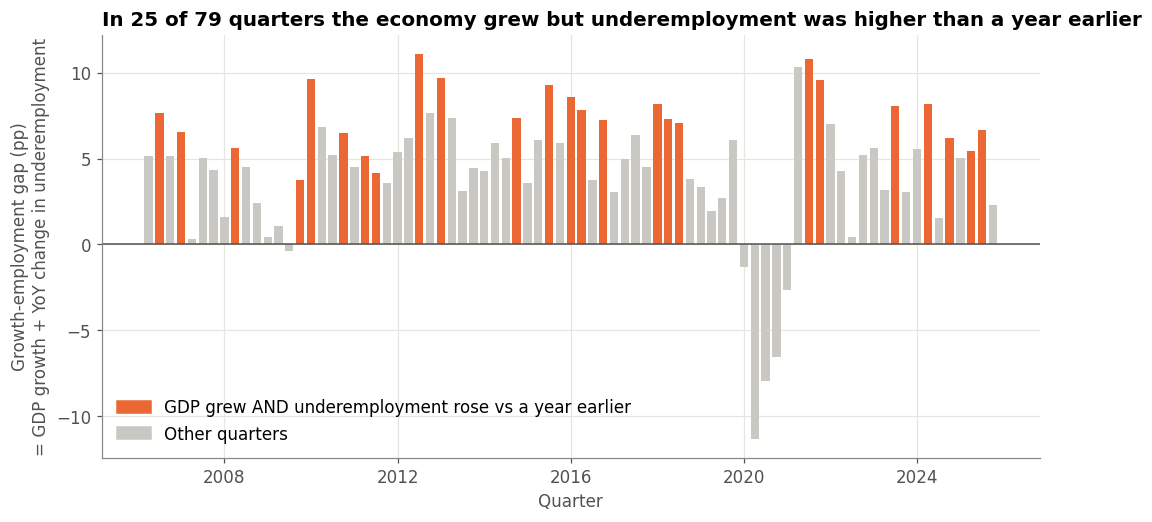

Jobless-growth quarters: 2006Q3, 2007Q1, 2008Q2, 2009Q4, 2010Q1, 2010Q4, 2011Q2, 2011Q3, 2012Q3, 2013Q1, 2014Q4, 2015Q3, 2016Q1, 2016Q2, 2016Q4, 2018Q1, 2018Q2, 2018Q3, 2021Q3, 2021Q4, 2023Q3, 2024Q2, 2024Q4, 2025Q2, 2025Q3


In [8]:
gap = df.dropna(subset=["growth_employment_gap"])
jobless = (gap["gdp_growth_yoy"] > 0) & (gap["underemployment_change_yoy"] > 0)

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(gap["quarter_start_date"], gap["growth_employment_gap"], width=70,
       color=np.where(jobless, ORANGE, "#c9c8c2"))
ax.axhline(0, color=INK, lw=1)
ax.set_ylabel("Growth-employment gap (pp)\n= GDP growth + YoY change in underemployment")
ax.set_xlabel("Quarter")
ax.set_title(f"In {jobless.sum()} of {len(gap)} quarters the economy grew "
             "but underemployment was higher than a year earlier")
handles = [plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color="#c9c8c2")]
ax.legend(handles, ["GDP grew AND underemployment rose vs a year earlier",
                    "Other quarters"], frameon=False, loc="lower left")
fig.savefig(FIG_DIR / "04_growth_employment_gap.png")
plt.show()

print("Jobless-growth quarters:", ", ".join(gap.loc[jobless, "quarter_id"]))

**Observation.** In 25 of 79 quarters (about one in three), GDP grew year on year while
underemployment was *higher* than in the same quarter a year earlier. These quarters appear in every
part of the series, from 2006 to 2025, including four of the six quarters from 2024Q2 to 2025Q3.

**Implication.** "Jobless growth", here meaning growth without job-quality gains, is not a one-off
episode but a recurring condition, roughly one quarter in three. Because the same-quarter comparison
removes the calendar effect, these quarters are not explained by seasonality.

**Possible action.** Track the growth-employment gap as a standing indicator in the Phase 5 dashboard,
and flag any quarter where GDP grows and underemployment rises year on year. For DOLE, a run of two or
more flagged quarters (as in 2018Q1–Q3 and 2021Q3–Q4) is a reasonable trigger for reviewing
livelihood and skills programs.

## 3. Inference Check (Week 15)

### Relationship or comparison
I am checking whether **last quarter's GDP growth** is related to **this quarter's change in the
underemployment rate**, after removing each quarter's usual seasonal move. Inflation is run through the
same test for comparison.

**In plain language:**
- *Starting assumption (null hypothesis):* there is no relationship. Any pattern in Chart 3 is what
  random pairing of quarters would produce.
- *Alternative:* there is a relationship, in either direction.

**Method.**
1. **Correlation (r).** One number for how closely the dots follow a straight line, from −1 to +1.
2. **Shuffle test (permutation test).** Shuffle the underemployment changes 10,000 times so they are
   paired with random quarters, and recompute r each time. This shows how big r gets **by pure chance**.
   The p-value is the share of shuffles with an r at least as far from zero as the real one. A small
   p-value (conventionally below 0.05) means chance rarely produces a pattern this strong.
3. **Resampling range (bootstrap 95 % interval).** Redraw the 82 quarters with replacement 10,000 times
   and recompute r. The middle 95 % of those values is the range of correlations consistent with this
   data.
4. **Robustness.** Repeat everything without the eight pandemic quarters (2020Q1–2021Q4).
5. **Keeping time order.** Steps 2 and 3 treat every quarter as independent of the one before. The
   table below shows that is not true, so two time-aware versions run alongside them:
   - *Circular shift:* instead of shuffling, slide the underemployment series along the predictor
     (wrapping the end round to the start) in every possible way. Each quarter keeps its neighbours.
   - *Year-block bootstrap:* redraw runs of four consecutive quarters (one year) instead of single
     quarters, so each draw keeps the series' rhythm.

Plain NumPy, fixed random seed, so the numbers below reproduce exactly.

In [9]:
def lag1_autocorr(values):
    values = values.dropna().to_numpy()
    return np.corrcoef(values[:-1], values[1:])[0, 1]

pd.Series({
    "Next change in underemployment (seasonal removed)": lag1_autocorr(df["change_adj"]),
    "GDP growth, last quarter": lag1_autocorr(df["gdp_growth_yoy_lag1"]),
    "Inflation, last quarter": lag1_autocorr(df["inflation_yoy_lag1"]),
}, name="correlation with the previous quarter").round(2).to_frame()

,correlation with the previous quarter
Next change in underemployment (seasonal removed),-0.39
"GDP growth, last quarter",0.72
"Inflation, last quarter",0.87


**How much each quarter depends on the one before.** The two predictors move slowly: a quarter's GDP
growth and inflation are close to the previous quarter's (+0.72 and +0.87). Underemployment changes do
the opposite (−0.39): a rise tends to be followed by a fall, the signature of survey-to-survey bounce.
When one series follows itself and the other reverses itself, the independent-quarter tests in steps
2–3 are *too cautious*: their p-values come out larger than they should. The time-aware columns
correct for this.

In [10]:
def correlation_test(x, y, n=10_000, seed=0, block=4):
    ok = x.notna() & y.notna()
    x, y = x[ok].to_numpy(), y[ok].to_numpy()
    rng = np.random.default_rng(seed)
    r = np.corrcoef(x, y)[0, 1]
    shuffled = np.array([np.corrcoef(x, rng.permutation(y))[0, 1] for _ in range(n)])
    rows = rng.integers(0, len(x), (n, len(x)))
    boot = np.array([np.corrcoef(x[i], y[i])[0, 1] for i in rows])
    lo, hi = np.percentile(boot, [2.5, 97.5])
    # Time-aware versions: every circular shift of y, and bootstrap draws of whole years.
    shifted = np.array([np.corrcoef(x, np.roll(y, k))[0, 1] for k in range(1, len(y))])
    starts = rng.integers(0, len(x) - block + 1, (n, -(-len(x) // block)))
    years = (starts[:, :, None] + np.arange(block)).reshape(n, -1)[:, :len(x)]
    year_boot = np.array([np.corrcoef(x[i], y[i])[0, 1] for i in years])
    year_lo, year_hi = np.percentile(year_boot, [2.5, 97.5])
    return {"n": len(x), "r": r,
            "p (shuffle)": (np.abs(shuffled) >= abs(r)).mean(),
            "95% low": lo, "95% high": hi,
            "p (time order kept)": (np.abs(shifted) >= abs(r)).mean(),
            "95% low (year blocks)": year_lo, "95% high (year blocks)": year_hi}

results = []
for col, name in [("gdp_growth_yoy_lag1", "GDP growth (last quarter)"),
                  ("inflation_yoy_lag1", "Inflation (last quarter)")]:
    for label, rows in [("all quarters", df.index == df.index), ("excl. 2020-21", ~COVID)]:
        res = correlation_test(df.loc[rows, col], df.loc[rows, "change_adj"])
        results.append({"predictor": name, "sample": label, **res})

results = pd.DataFrame(results).set_index(["predictor", "sample"])
results.round(3)

n      r  p (shuffle)  95% low  \
predictor                 sample                                           
GDP growth (last quarter) all quarters   82 -0.001        0.994   -0.270   
                          excl. 2020-21  74 -0.163        0.169   -0.323   
Inflation (last quarter)  all quarters   82 -0.095        0.395   -0.303   
                          excl. 2020-21  74 -0.092        0.430   -0.316   

                                         95% high  p (time order kept)  \
predictor                 sample                                         
GDP growth (last quarter) all quarters      0.185                1.000   
                          excl. 2020-21     0.003                0.068   
Inflation (last quarter)  all quarters      0.141                0.099   
                          excl. 2020-21     0.158                0.205   

                                         95% low (year blocks)  \
predictor                 sample                                 
GDP growth (last quarter) all quarters                  -0.256   
                          excl. 2020-21                 -0.302   
Inflation (last quarter)  all quarters                  -0.182   
                          excl. 2020-21                 -0.182   

                                         95% high (year blocks)  
predictor                 sample                                 
GDP growth (last quarter) all quarters                    0.127  
                          excl. 2020-21                  -0.056  
Inflation (last quarter)  all quarters                    0.060  
                          excl. 2020-21                   0.068

### What the data shows
Across all 82 quarters, last quarter's GDP growth and the next change in underemployment are
uncorrelated (r = −0.00; p = 0.99 by shuffling, 1.00 with time order kept). Inflation is weak too
(r = −0.09; p = 0.40, or 0.10 with time order kept), and both of its intervals include zero.

Without the pandemic quarters, the GDP correlation moves to r = −0.16: faster growth is followed by a
slightly *larger fall* in underemployment. The independent-quarter test calls this chance (p = 0.17).
The time-aware test is less sure (p = 0.07), and its year-block interval, −0.30 to −0.06, does not
include zero. That is weak evidence, not an established link: p is still above 0.05, and it is the
strongest of four results, two of which use a sample chosen after seeing the pandemic's effect. Four
tries make one borderline result more likely by chance alone.

### What I can say carefully
- Over 2005–2025 as a whole, last quarter's GDP growth and inflation **did not anticipate** the next
  quarter's change in national underemployment in any way this data can detect.
- If a link exists, it is weak. Every interval excludes anything stronger than about |r| = 0.32, so GDP
  growth would explain at most about 10 % of the quarter-to-quarter swings.
- Outside the pandemic there is weak evidence of a link in the hopeful direction (more growth, slightly
  less underemployment next quarter). It is a hypothesis to re-test as new quarters arrive, not a finding.

### What I cannot conclude
- **"GDP growth has no effect on jobs."** Not finding a relationship is not proof that none exists.
  82 quarters can only detect fairly strong links; a small real effect would be missed. Chart 1 shows a
  long-run decline that this one-quarter test is not designed to see.
- **Anything causal, in either direction.** This is observational data. Many things move both series at
  once: typhoons and harvests, remittances, government hiring, the 2020 lockdowns. A correlation,
  or its absence, cannot separate them.
- **Anything about other lags.** Only a one-quarter lag was tested. Growth may reach jobs over a year or
  more, which is a separate question.
- **Anything regional or sectoral.** These are national averages; opposite movements in different
  regions or industries can cancel out.
- **Fine-grained comparisons across 2021.** The survey went monthly in 2021 and the round-month value
  runs about 1.17 pp above the three-month average from then on, so small level differences across that
  boundary are partly a measurement artefact.

## 4. Overall Takeaway

**Answer to the problem statement.** No: in 2005–2025, quarter-to-quarter changes in Philippine
underemployment **could not be anticipated** from the previous quarter's GDP growth or inflation. The
largest predictable part of those changes is the calendar: underemployment usually falls in the October
round and rises in January. Over twenty years, underemployment did fall as the economy grew, but
in about one quarter in three the economy grew while underemployment was higher than a year earlier.
Growth is associated with better jobs in the long run. It is not a reliable signal of better jobs in any
particular quarter. Outside the pandemic there is a weak hint that faster growth precedes slightly larger
falls in underemployment, worth re-testing as new quarters arrive.

**What this means for DOLE, NEDA and analysts, most important first**

1. **Measure job quality directly.** Do not read GDP growth as evidence that underemployment is improving.
   Report the underemployment rate alongside every growth headline.
2. **Compare like with like.** Judge each LFS release against the same quarter a year earlier. A Q4 drop
   on its own is expected and not good news.
3. **Monitor the gap.** Make the growth-employment gap and the "grew but worsened" flag a standing
   indicator. This becomes the core of the Phase 5 dashboard.

**Next step.** Phase 5 builds the dashboard around Chart 4's flag and benchmarks a simple forecast
against the no-change baseline on a time-ordered split, as the README sets out.

## Check: the numbers quoted in the text

The markdown above quotes numbers by hand. This cell recomputes each one and fails if the data has
moved, so a re-run after a new PSA pull cannot leave the prose silently out of date.

In [11]:
gdp, infl = "GDP growth (last quarter)", "Inflation (last quarter)"
quoted = {
    "underemployment mean": (summary.loc["underemployment_rate", "mean"], 17.64),
    "underemployment median": (summary.loc["underemployment_rate", "median"], 18.02),
    "underemployment std dev": (summary.loc["underemployment_rate", "std dev"], 3.04),
    "underemployment min": (summary.loc["underemployment_rate", "min"], 11.71),
    "underemployment max": (summary.loc["underemployment_rate", "max"], 26.14),
    "QoQ change mean": (summary.loc["underemployment_change_qoq", "mean"], -0.17),
    "QoQ change std dev": (summary.loc["underemployment_change_qoq", "std dev"], 2.07),
    "GDP growth mean": (summary.loc["gdp_growth_yoy", "mean"], 5.06),
    "GDP growth median": (summary.loc["gdp_growth_yoy", "median"], 6.10),
    "GDP growth skew": (summary.loc["gdp_growth_yoy", "skew"], -3.42),
    "inflation mean": (summary.loc["inflation_yoy", "mean"], 3.80),
    "gap mean": (summary.loc["growth_employment_gap", "mean"], 4.64),
    "Q4 mean change": (season.loc[4, "mean"], -1.67),
    "Q1 mean change": (season.loc[1, "mean"], 0.72),
    "Q4 years falling": ((df.loc[df["quarter_num"] == 4, "underemployment_change_qoq"] < 0).sum(), 14),
    "jobless-growth quarters": (jobless.sum(), 25),
    "gap quarters": (len(gap), 79),
    "GDP r, all": (results.loc[(gdp, "all quarters"), "r"], -0.00),
    "GDP p shuffle, all": (results.loc[(gdp, "all quarters"), "p (shuffle)"], 0.99),
    "inflation r, all": (results.loc[(infl, "all quarters"), "r"], -0.09),
    "inflation p shuffle, all": (results.loc[(infl, "all quarters"), "p (shuffle)"], 0.40),
    "inflation p time order, all": (results.loc[(infl, "all quarters"), "p (time order kept)"], 0.10),
    "GDP r, excl. pandemic": (results.loc[(gdp, "excl. 2020-21"), "r"], -0.16),
    "GDP p shuffle, excl.": (results.loc[(gdp, "excl. 2020-21"), "p (shuffle)"], 0.17),
    "GDP p time order, excl.": (results.loc[(gdp, "excl. 2020-21"), "p (time order kept)"], 0.07),
    "GDP year-block low, excl.": (results.loc[(gdp, "excl. 2020-21"), "95% low (year blocks)"], -0.30),
    "GDP year-block high, excl.": (results.loc[(gdp, "excl. 2020-21"), "95% high (year blocks)"], -0.06),
}
stale = {label: f"text says {expected}, data says {actual:.3f}"
         for label, (actual, expected) in quoted.items()
         if not np.isclose(actual, expected, atol=0.005)}
assert not stale, f"Update the markdown: {stale}"
print(f"all {len(quoted)} quoted numbers match the data")

all 27 quoted numbers match the data
